In [158]:
library(tidyverse)
library(ggrepel)
library(clusterProfiler)
library(msigdbr)
library(stringr)

library(pheatmap)

theme_set(theme_bw() + theme(text=element_text(size=15), panel.grid=element_blank()))

In [363]:
col.data <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_coldata.tsv", sep='\t')
row.data <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_rowdata.tsv", sep='\t')
tpm <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_TPMs.tsv", sep='\t')

#read in DEGs
ifn_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/IFNy_1h_DEGs.tsv", sep='\t')
ifn_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/IFNy_6h_DEGs.tsv", sep='\t')
dex_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/Dex_1h_DEGs.tsv", sep='\t')
dex_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/Dex_6h_DEGs.tsv", sep='\t')

brm_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_6h_DEGs.tsv", sep='\t')

brm_ifn_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_IFNy_v_IFNy_6h_DEGs.tsv", sep='\t')
brm_dex_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_Dex_v_Dex_6h_DEGs.tsv", sep='\t')

brm_ifn_veh_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_IFNy_v_Veh_6h_DEGs.tsv", sep='\t')
brm_dex_veh_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_Dex_v_Veh_6h_DEGs.tsv", sep='\t')

ifn_up <- (ifn_1h$change=="up"  | ifn_6h$change=="up")
dex_up <- (dex_1h$change=="up"  | dex_6h$change=="up")

In [23]:
col.data_ifn <- col.data[grep("IFN|Veh",col.data$group),]
tpm_ifn <- tpm[,grep("IFN|Veh",col.data$group)] %>% `colnames<-`(paste0(col.data_ifn$group, "_", col.data_ifn$replicate))
head(tpm_ifn)

col.data_dex <- col.data[grep("Dex|Veh",col.data$group),]
tpm_dex <- tpm[,grep("Dex|Veh",col.data$group)] %>% `colnames<-`(paste0(col.data_dex$group, "_", col.data_dex$replicate))
head(tpm_dex)

,BRM_IFN_T1_r1,BRM_IFN_T1_r2,IFN_T1_r1,IFN_T1_r2,Veh_T1_r1,Veh_T1_r2,BRM_IFN_T6_r1,BRM_IFN_T6_r2,IFN_T6_r1,IFN_T6_r2,Veh_T6_r1,Veh_T6_r2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,57.89,53.07,55.57,60.77,57.17,60.77,59.02,59.23,60.71,59.59,64.56,57.29
2,12.86,14.88,17.98,10.78,14.29,13.70,23.96,22.85,13.30,16.77,12.54,15.56
3,450.90,401.70,438.32,411.00,396.87,382.82,567.30,581.59,625.20,568.06,456.13,402.24
4,22.17,21.91,25.35,23.60,24.38,20.99,22.66,20.54,18.56,22.07,21.92,25.48
5,9.59,11.00,10.30,11.14,11.55,10.03,19.03,16.87,13.86,12.30,9.96,10.29
6,9.99,10.36,10.14,12.03,9.75,10.69,5.81,8.38,8.01,8.09,11.73,10.44


,BRM_Dex_T1_r1,BRM_Dex_T1_r2,Dex_T1_r1,Dex_T1_r2,Veh_T1_r1,Veh_T1_r2,BRM_Dex_T6_r1,BRM_Dex_T6_r2,Dex_T6_r1,Dex_T6_r2,Veh_T6_r1,Veh_T6_r2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,60.73,56.71,58.87,54.82,57.17,60.77,60.43,60.89,63.03,57.85,64.56,57.29
2,13.33,12.32,16.15,14.89,14.29,13.70,22.93,25.07,12.13,14.80,12.54,15.56
3,402.33,363.47,380.40,356.99,396.87,382.82,218.72,235.92,269.01,241.99,456.13,402.24
4,22.11,20.70,22.21,24.71,24.38,20.99,17.08,19.47,16.21,18.05,21.92,25.48
5,10.23,10.87,9.65,10.69,11.55,10.03,17.28,18.26,11.32,10.96,9.96,10.29
6,9.06,11.37,10.87,10.42,9.75,10.69,5.38,8.30,12.39,12.57,11.73,10.44


In [220]:
hm_scale <- function(tpms,coldata,groups, scale="none", breaks=NA, colors=c("white", "red")){
    temp <- tpms[,coldata$group %in% groups] %>% +1 %>% log2()
    temp_coldata <- coldata[coldata$group %in% groups,]
    max <- max(temp) + 1
    
    d <- dist(scale(temp))
    h <- hclust(d)
    
    pheatmap(temp[h$order,], 
             color=colorRampPalette(colors)(100), 
             cluster_rows=if (scale=="row") TRUE else FALSE, 
             cluster_cols=FALSE, 
             border_col=NA, 
             labels_col=temp_coldata$group,
             show_rownames=FALSE,
             scale=scale,
             breaks= breaks,
             cellheight=1, 
             main=paste("n=", nrow(temp)))
}

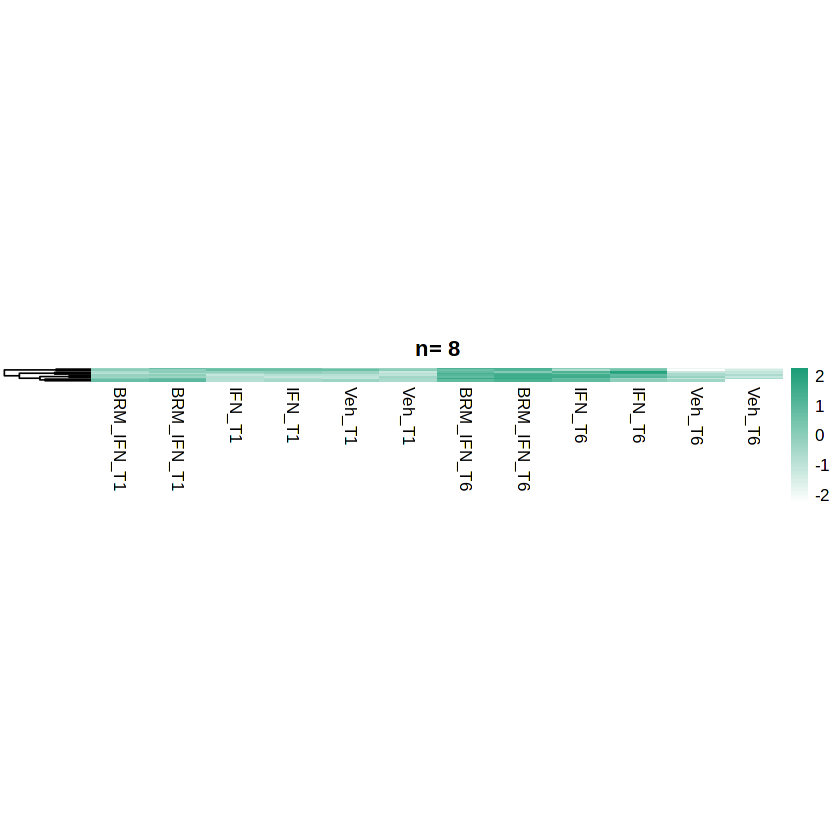

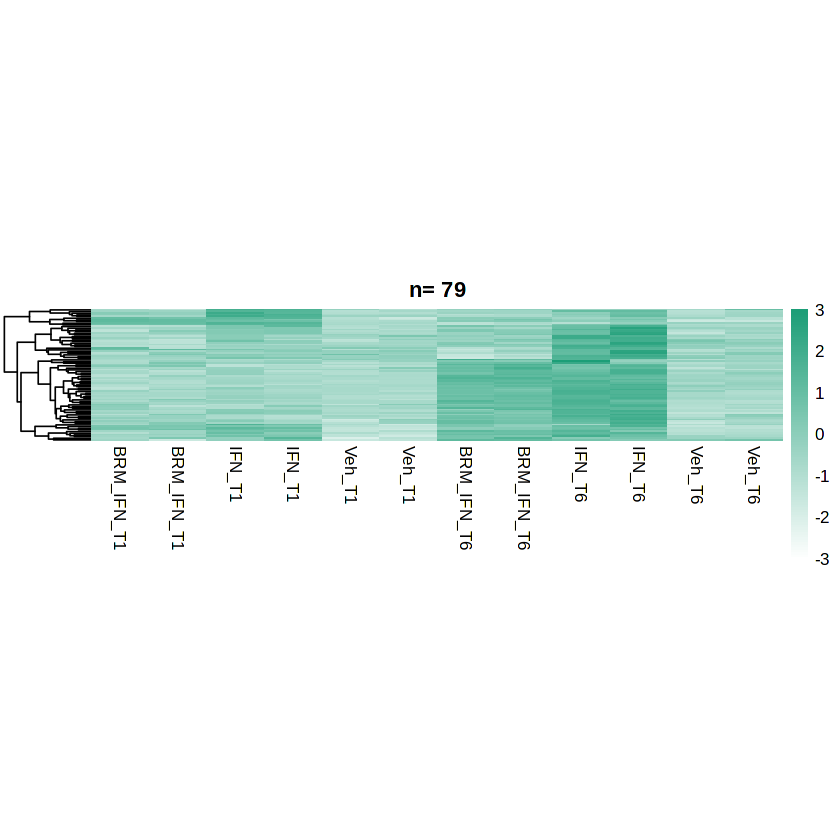

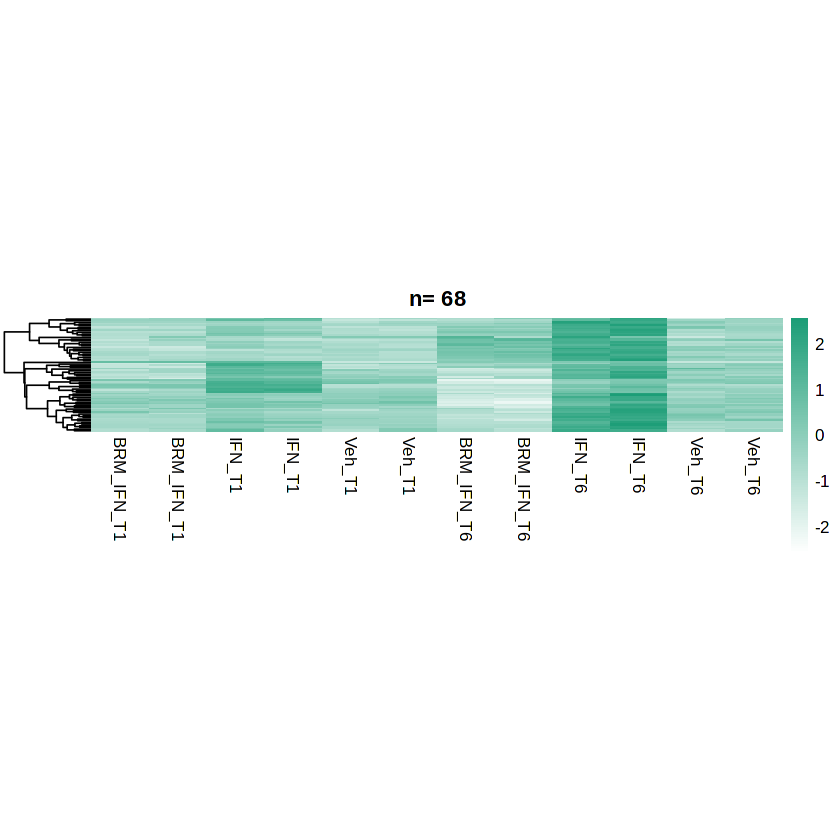

In [224]:
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="up"),-13], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="ns"),-13], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="down"),-13], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))

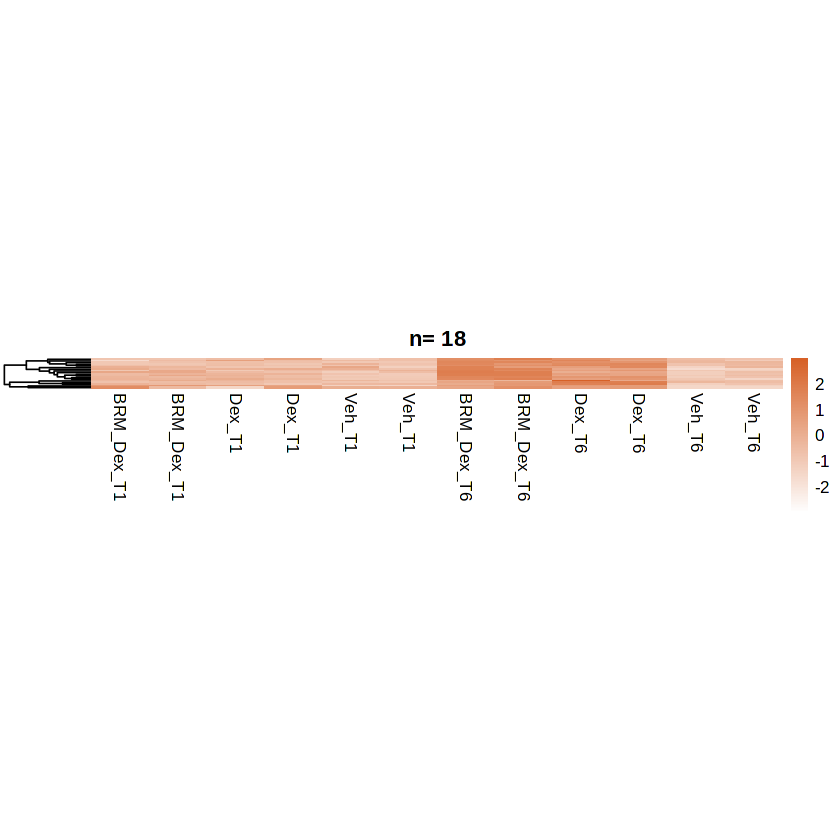

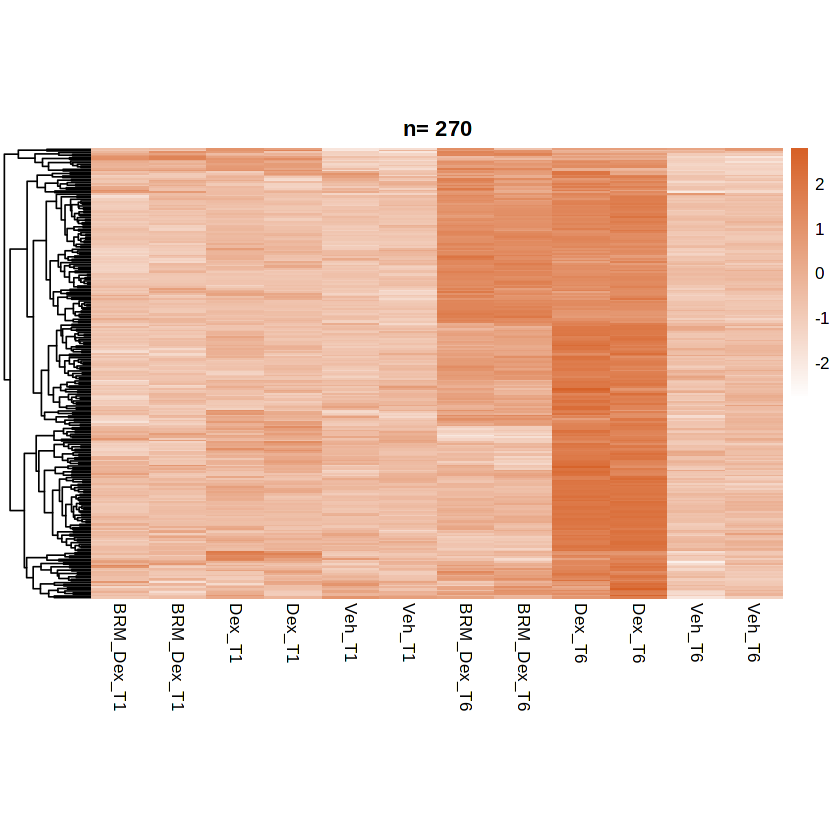

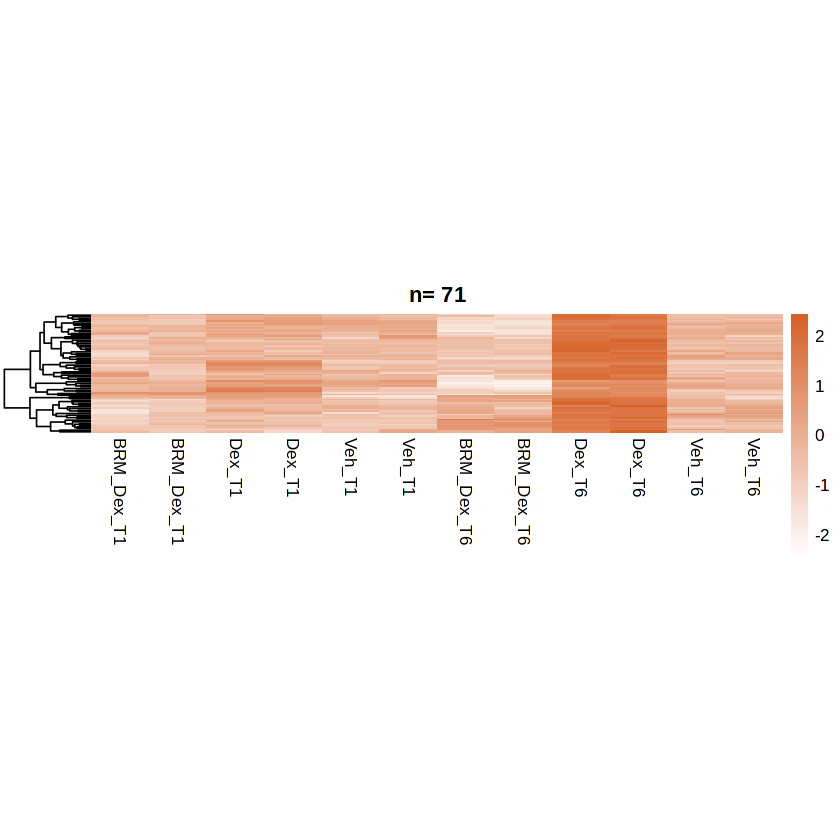

In [225]:
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="up"),-13], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="ns"),-13], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="down"),-13], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))

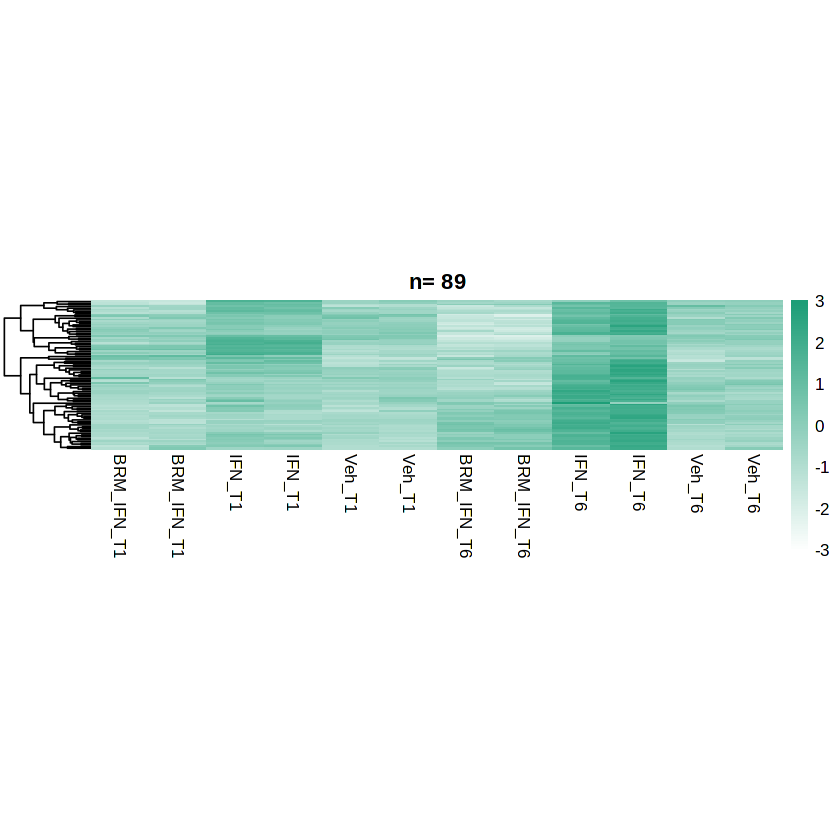

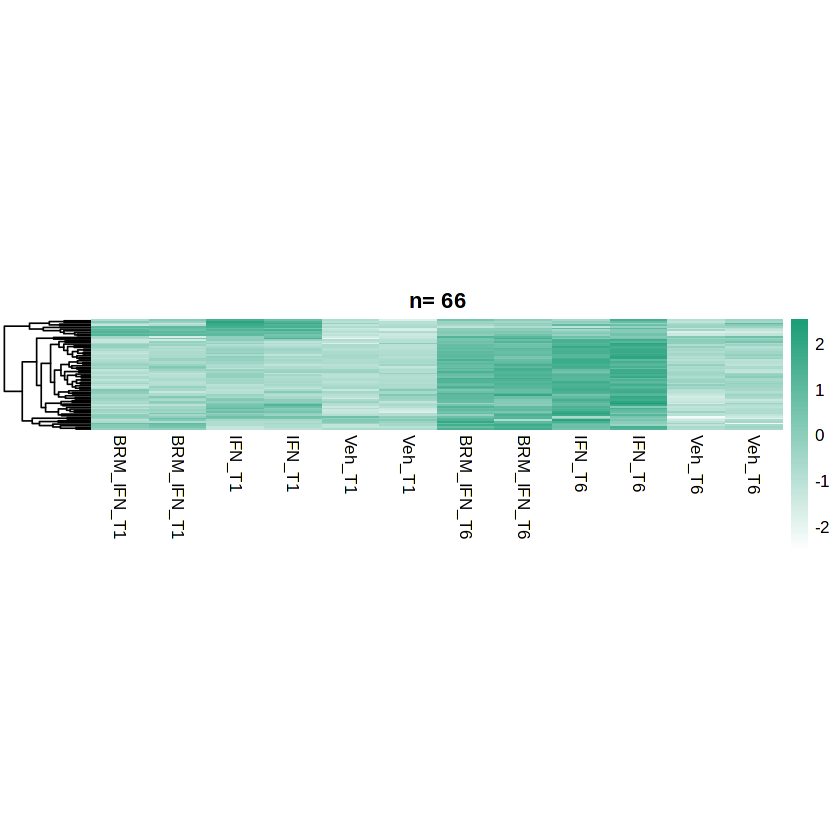

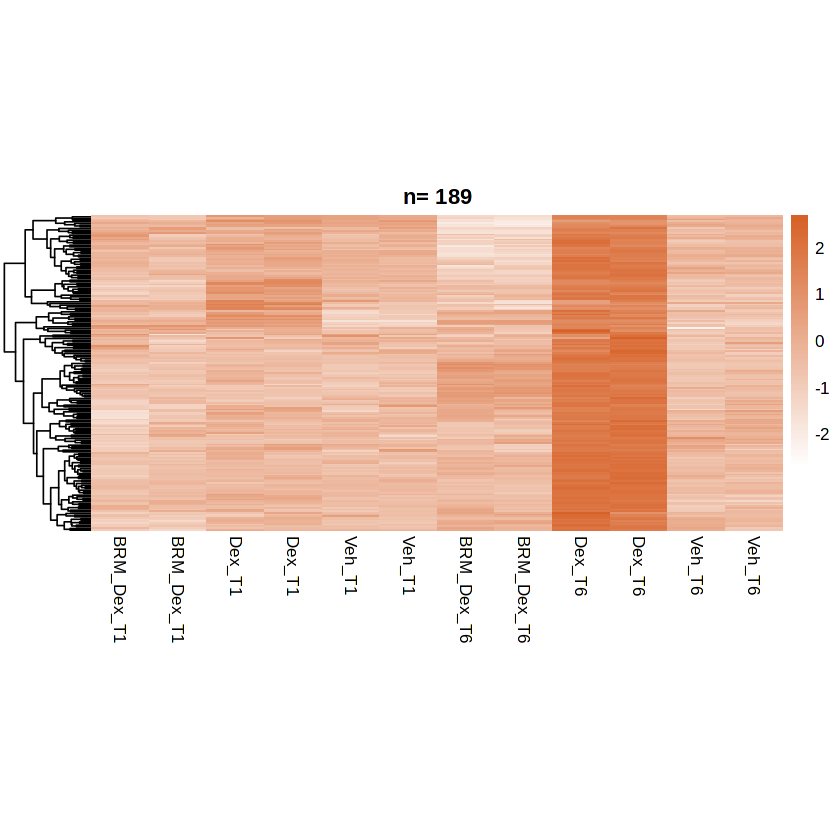

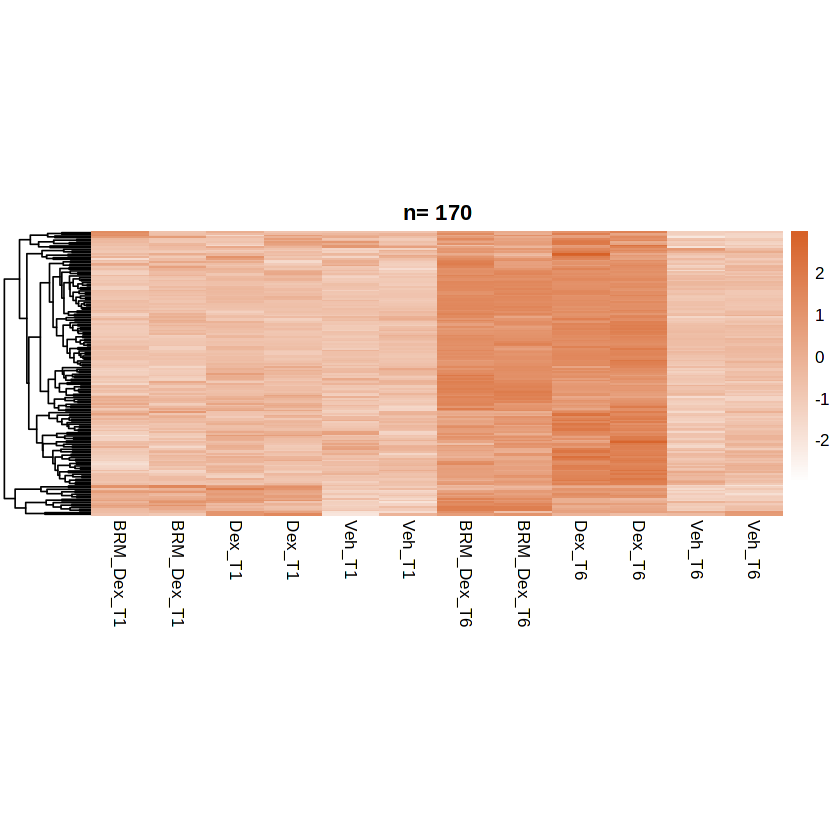

In [226]:
hm_scale(tpm_ifn[which(ifn_up & brm_ifn_6h$change == "down") ,-13], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))
hm_scale(tpm_ifn[which(ifn_up & brm_ifn_6h$change != "down") ,-13], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))

hm_scale(tpm_dex[which(dex_up & brm_dex_6h$change == "down") ,-13], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_dex_6h$change != "down") ,-13], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))



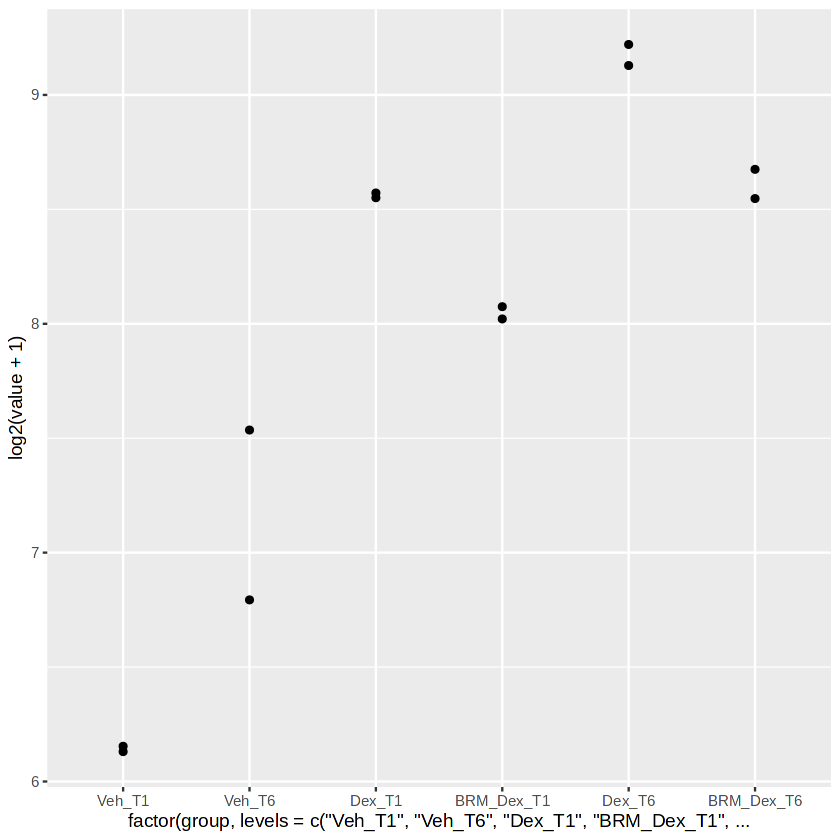

In [53]:
targets <- c("REDD1")
tpm_dex[dex_up,] %>% filter(gene %in% targets) %>% 
    pivot_longer(!gene) %>%
    mutate(group=gsub("_r.$", "", name)) %>%
    ggplot(aes(x=factor(group, levels=c("Veh_T1", "Veh_T6", "Dex_T1", "BRM_Dex_T1", "Dex_T6", "BRM_Dex_T6")),y=log2(value+1))) + geom_point()



Registered S3 methods overwritten by 'treeio':
  method              from    
  MRCA.phylo          tidytree
  MRCA.treedata       tidytree
  Nnode.treedata      tidytree
  Ntip.treedata       tidytree
  ancestor.phylo      tidytree
  ancestor.treedata   tidytree
  child.phylo         tidytree
  child.treedata      tidytree
  full_join.phylo     tidytree
  full_join.treedata  tidytree
  groupClade.phylo    tidytree
  groupClade.treedata tidytree
  groupOTU.phylo      tidytree
  groupOTU.treedata   tidytree
  is.rooted.treedata  tidytree
  nodeid.phylo        tidytree
  nodeid.treedata     tidytree
  nodelab.phylo       tidytree
  nodelab.treedata    tidytree
  offspring.phylo     tidytree
  offspring.treedata  tidytree
  parent.phylo        tidytree
  parent.treedata     tidytree
  root.treedata       tidytree
  rootnode.phylo      tidytree
  sibling.phylo       tidytree

clusterProfiler v4.6.2  For help: https://yulab-smu.top/biomedical-knowledge-mining-book/

If you use clusterProf

In [137]:
#all_gene_sets = msigdbr(species = "Homo sapiens")
unique(all_gene_sets$gs_subcat)
# [optional] filter subcategories to focus those on those that are most relevent

nrow(all_gene_sets)
keeper.cats <- c("CP:KEGG", "GO:BP", "GO:MF", "GO:CC")
all_gene_sets <- all_gene_sets[which(all_gene_sets$gs_subcat %in% keeper.cats),]
nrow(all_gene_sets)


[1] "GO:BP"       "GO:CC"       "IMMUNESIGDB" "GO:MF"       "CP:KEGG"

[1] 2042994

[1] 976105

In [129]:
table(all_gene_sets$gs_subcat)


                            CGN             CGP              CM              CP 
         214578           49342          426486           56738            4197 
    CP:BIOCARTA         CP:KEGG          CP:PID     CP:REACTOME CP:WIKIPATHWAYS 
           5515           16283            8722           99851           33849 
          GO:BP           GO:CC           GO:MF             HPO     IMMUNESIGDB 
         721379          115769          122674          464649         1066889 
 MIR:MIR_Legacy       MIR:MIRDB        TFT:GTRD  TFT:TFT_Legacy             VAX 
          36362          397724          268672          170053           52075 

In [138]:
# Convert format to make data frame compatible with GO/GSEA tools

msigdbr_list = split(x = all_gene_sets$gene_symbol, f = all_gene_sets$gs_name)
length(msigdbr_list)
msigdbr_t2g = all_gene_sets %>% dplyr::distinct(gs_name, gene_symbol) %>% as.data.frame()
nrow(msigdbr_t2g)
head(msigdbr_t2g)


[1] 10588

[1] 853744

,gs_name,gene_symbol
,<chr>,<chr>
1,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,AASDHPPT
2,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,ALDH1L1
3,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,ALDH1L2
4,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,MTHFD1
5,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,MTHFD1L
6,GOBP_10_FORMYLTETRAHYDROFOLATE_METABOLIC_PROCESS,MTHFD2L


In [167]:
tpm_dex$gene <- row.data$gene_name
foreground.dex_up_brm_down <- tpm_dex[which(dex_up & brm_dex_6h$change == "down"),"gene"]
foreground.dex_up_brm_ns <- tpm_dex[which(dex_up & brm_dex_6h$change != "down"),"gene"]
#foreground.dex_up_brm_up <- tpm_dex[which(dex_up & brm_dex_6h$change == "up"),"gene"]
background <- tpm_dex[,"gene",]

tpm_ifn$gene <- row.data$gene_name
foreground.ifn_up_brm_down <- tpm_ifn[which(ifn_up & brm_ifn_6h$change == "down"),"gene"]
foreground.ifn_up_brm_ns <- tpm_ifn[which(ifn_up & brm_ifn_6h$change != "down"),"gene"]
#foreground.ifn_up_brm_up <- tpm_ifn[which(ifn_up & brm_ifn_6h$change == "up"),"gene"]


In [168]:
go.res.dex_up_brm_down <- enricher(gene = foreground.dex_up_brm_down, universe = background, TERM2GENE = msigdbr_t2g, minGSSize = 10, pvalueCutoff=1, qvalueCutoff=1)
go.res.dex_up_brm_ns <- enricher(gene = foreground.dex_up_brm_ns, universe = background, TERM2GENE = msigdbr_t2g, minGSSize = 10, pvalueCutoff=1, qvalueCutoff=1)

go.res.ifn_up_brm_down <- enricher(gene = foreground.ifn_up_brm_down, universe = background, TERM2GENE = msigdbr_t2g, minGSSize = 10, pvalueCutoff=1, qvalueCutoff=1)
go.res.ifn_up_brm_ns <- enricher(gene = foreground.ifn_up_brm_ns, universe = background, TERM2GENE = msigdbr_t2g, minGSSize = 10, pvalueCutoff=1, qvalueCutoff=1)

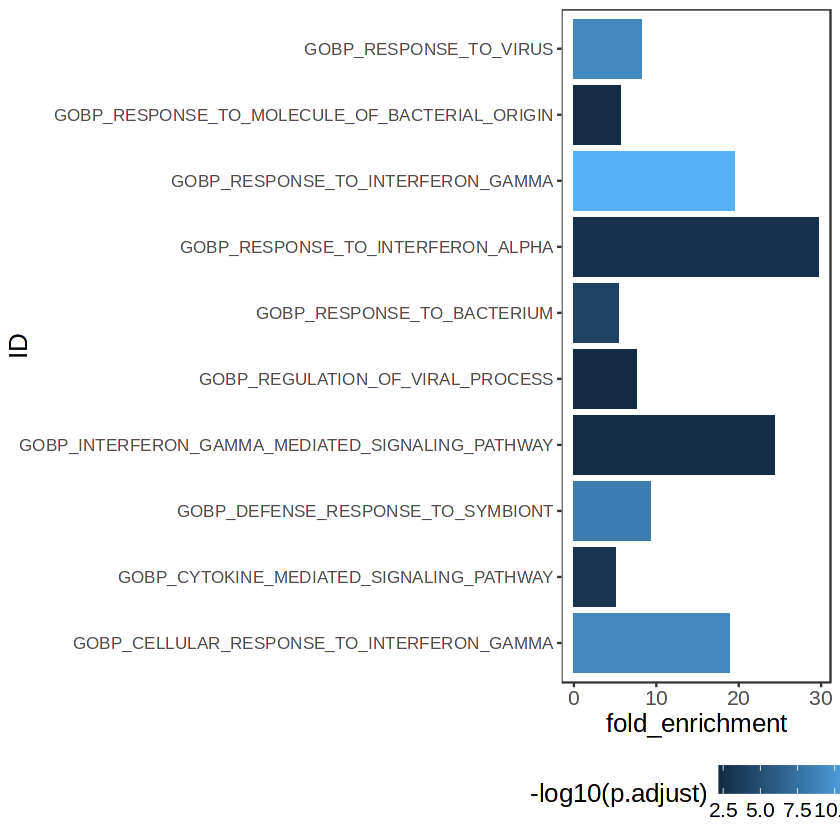

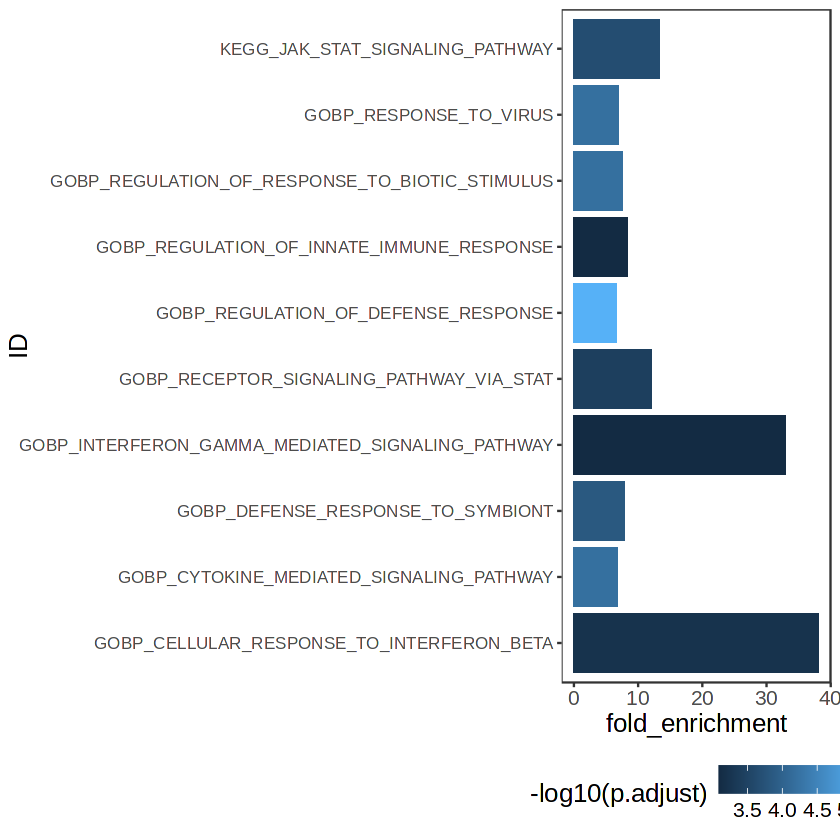

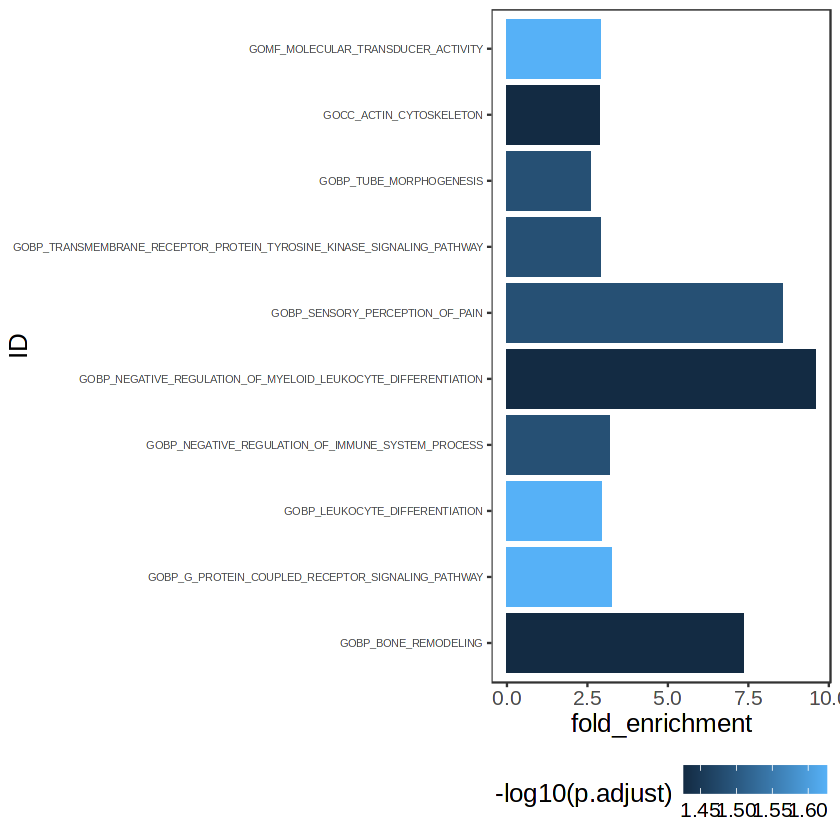

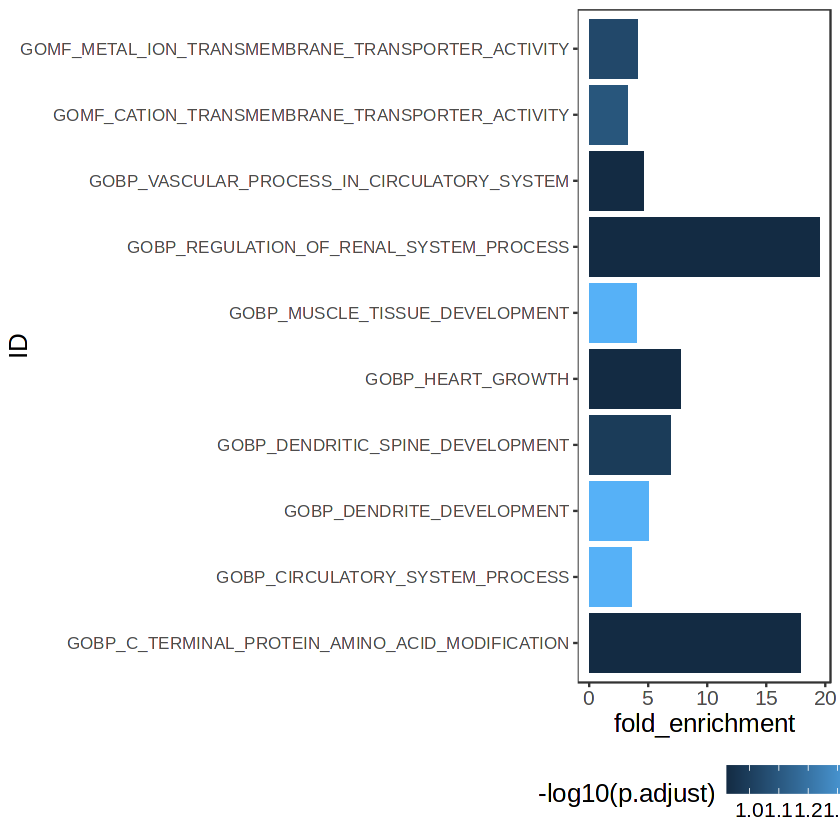

In [407]:
#go.res.dex_up_brm_down %>% data.frame() %>% filter(p.adjust < .05) %>% arrange((p.adjust)) %>% head(10)
#go.res.dex_up_brm_ns %>% data.frame()  %>% filter(p.adjust < .05) %>% arrange((p.adjust)) %>% head(10)

go.res.ifn_up_brm_down %>% data.frame() %>% filter(p.adjust < .05) %>% arrange((p.adjust)) %>% head(10) %>% ggplot(aes(y=ID, x=fold_enrichment)) + geom_col(aes(fill=-log10(p.adjust))) + theme(legend.position="bottom", axis.text.y=element_text(size=10))
go.res.ifn_up_brm_ns %>% data.frame() %>% filter(p.adjust < .05) %>% arrange((p.adjust)) %>% head(10) %>% ggplot(aes(y=ID, x=fold_enrichment)) + geom_col(aes(fill=-log10(p.adjust))) + theme(legend.position="bottom", axis.text.y=element_text(size=10))

go.res.dex_up_brm_down %>% data.frame() %>% filter(p.adjust < .05) %>% arrange((p.adjust)) %>% head(10) %>% ggplot(aes(y=ID, x=fold_enrichment)) + geom_col(aes(fill=-log10(p.adjust))) + theme(legend.position="bottom", axis.text.y=element_text(size=6))
go.res.dex_up_brm_ns %>% data.frame()  %>% arrange((p.adjust)) %>% head(10) %>% ggplot(aes(y=ID, x=fold_enrichment)) + geom_col(aes(fill=-log10(p.adjust))) + theme(legend.position="bottom", axis.text.y=element_text(size=10))

In [211]:
go.res.ifn_up_brm_down <- go.res.ifn_up_brm_down %>% data.frame() %>% mutate(fold_enrichment = sapply(GeneRatio, FUN=function(x) eval(parse(text = x))) / sapply(BgRatio, FUN=function(x) eval(parse(text = x))))
go.res.ifn_up_brm_ns<- go.res.ifn_up_brm_ns %>% data.frame() %>% mutate(fold_enrichment = sapply(GeneRatio, FUN=function(x) eval(parse(text = x))) / sapply(BgRatio, FUN=function(x) eval(parse(text = x))))
      
go.res.dex_up_brm_down <- go.res.dex_up_brm_down %>% data.frame() %>% mutate(fold_enrichment = sapply(GeneRatio, FUN=function(x) eval(parse(text = x))) / sapply(BgRatio, FUN=function(x) eval(parse(text = x))))
go.res.dex_up_brm_ns<- go.res.dex_up_brm_ns %>% data.frame() %>% mutate(fold_enrichment = sapply(GeneRatio, FUN=function(x) eval(parse(text = x))) / sapply(BgRatio, FUN=function(x) eval(parse(text = x))))


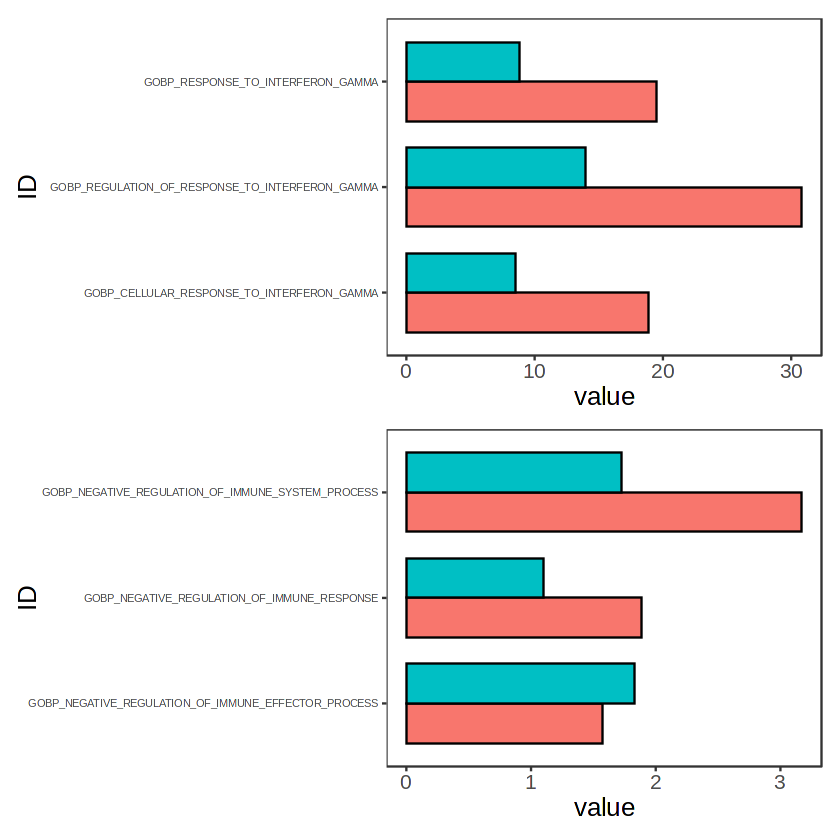

Saving 7 x 7 in image


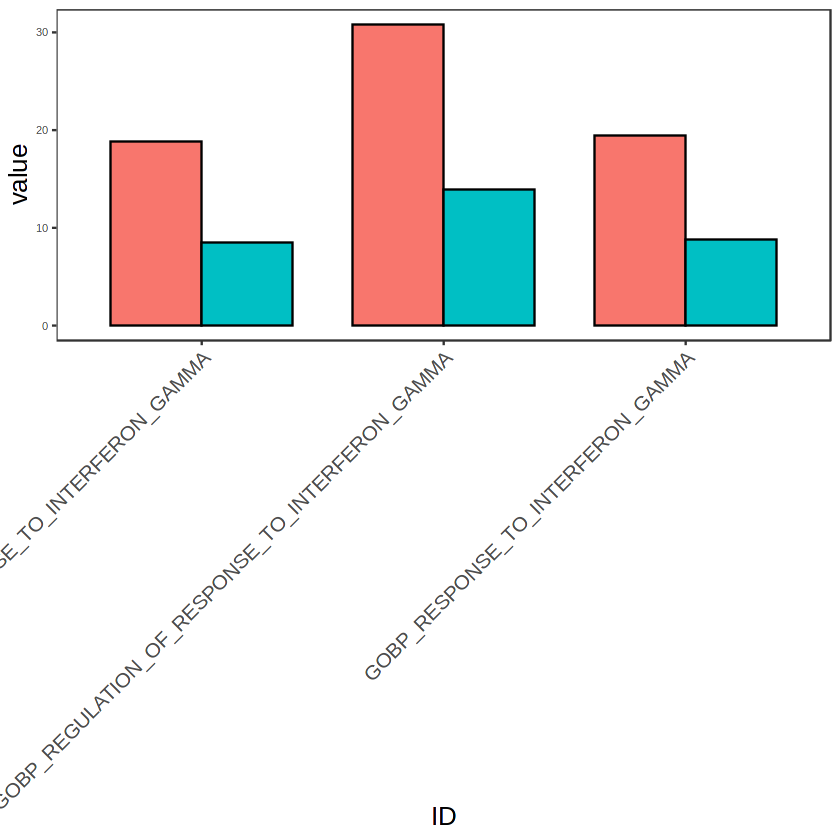

In [338]:
p1 <- inner_join(go.res.ifn_up_brm_down, go.res.ifn_up_brm_ns, by="ID") %>% 
    filter(grepl("RESPONSE_TO_INTERFERON_GAMMA",ID)) %>% select(ID, fold_enrichment.x, fold_enrichment.y) %>% pivot_longer(!ID) %>% 
    ggplot(aes(x=value, y=ID, fill=name)) + geom_col(width=.75,color="black",show.legend=FALSE, position=position_dodge()) + theme(axis.text.y=element_text(size=6)) 


p2 <- inner_join(go.res.dex_up_brm_down, go.res.dex_up_brm_ns, by="ID") %>% 
    filter(grepl("NEGATIVE_REGULATION_OF_IMMUNE",ID)) %>% select(ID, fold_enrichment.x, fold_enrichment.y) %>% pivot_longer(!ID) %>% 
    ggplot(aes(x=value, y=ID, fill=name)) + geom_col(width=.75,color="black",show.legend=FALSE, position=position_dodge()) + theme(axis.text.y=element_text(size=6)) 
p1 / p2
p1 + coord_flip() + theme(axis.text.x=element_text(angle=45, hjust=1))
ggsave("PanelF_GO_BAF_repressed_vs_nc.pdf")

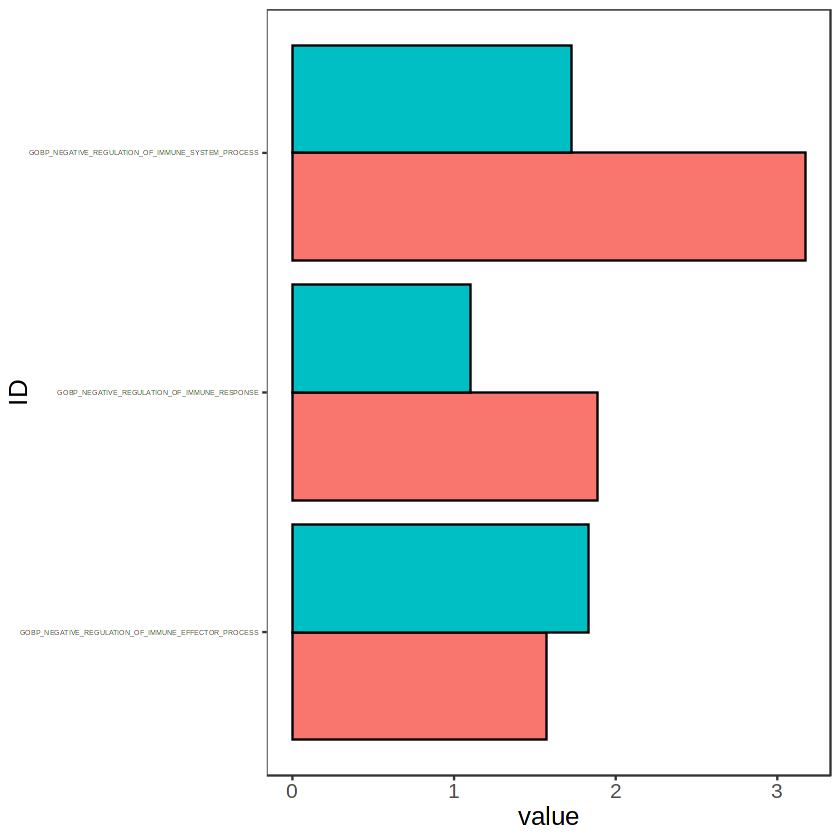

In [215]:
inner_join(go.res.dex_up_brm_down, go.res.dex_up_brm_ns, by="ID") %>% 
    filter(grepl("NEGATIVE_REGULATION_OF_IMMUNE",ID)) %>% select(ID, fold_enrichment.x, fold_enrichment.y) %>% pivot_longer(!ID) %>% 
    ggplot(aes(x=value, y=ID, fill=name)) + geom_col(color="black",show.legend=FALSE, position=position_dodge()) + theme(axis.text.y=element_text(size=4))

In [347]:
 inner_join(go.res.ifn_up_brm_down, go.res.ifn_up_brm_ns, by="ID") %>% 
    filter(grepl("RESPONSE_TO_INTERFERON_GAMMA",ID)) %>% select(ID, p.adjust.x, p.adjust.y)

ID,p.adjust.x,p.adjust.y
<chr>,<dbl>,<dbl>
GOBP_RESPONSE_TO_INTERFERON_GAMMA,1.427767e-12,0.01385776
GOBP_CELLULAR_RESPONSE_TO_INTERFERON_GAMMA,6.517164e-10,0.03933644
GOBP_REGULATION_OF_RESPONSE_TO_INTERFERON_GAMMA,9.387936e-03,0.30684709


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Saving 7 x 7 in image


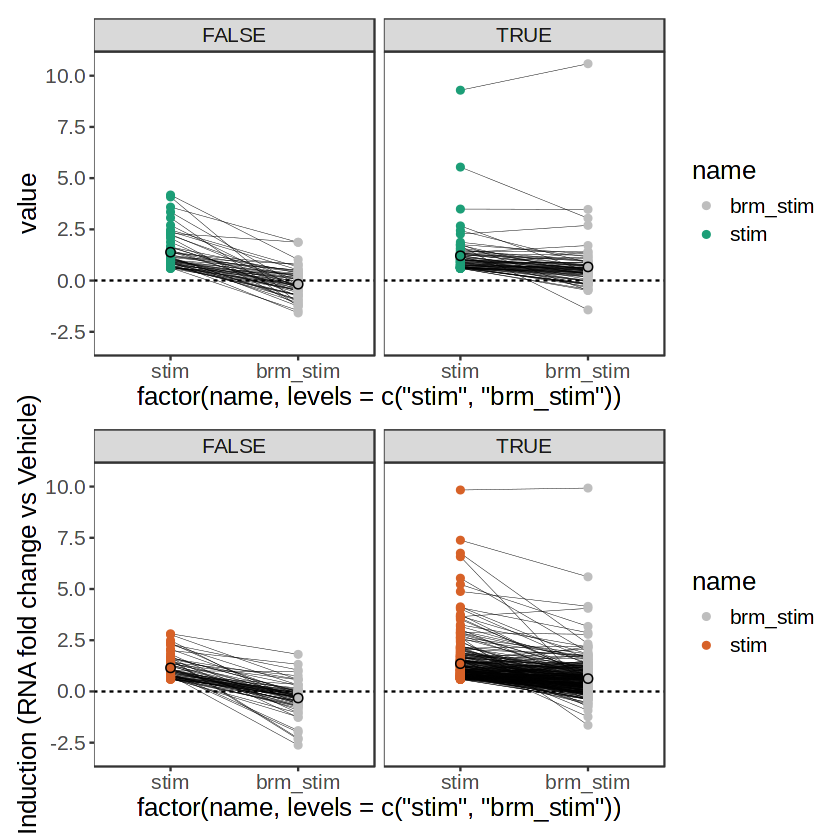

In [382]:
p1 <- inner_join(ifn_6h[ifn_6h$change=="up",], brm_ifn_veh_6h[ifn_6h$change=="up",], by="gene") %>% mutate(BAFdep=brm_6h[ifn_6h$change=="up","change"] != "down") %>% select(gene, BAFdep, stim=log2FoldChange.x, brm_stim=log2FoldChange.y) %>% pivot_longer(!c(BAFdep,gene)) %>%
    ggplot(aes(x=factor(name, levels=c("stim", "brm_stim")), y=value, group=gene, color=name)) + geom_hline(yintercept=0, linetype=2) + geom_line(linewidth=.1, color="black") + geom_point() + stat_summary(fun=mean, geom="point", aes(group=name),  shape=21,size=2,color="black") + 
    facet_wrap(~BAFdep, ncol=2) + scale_color_manual(values=c("grey", "#1c9e77")) + coord_cartesian(ylim=c(-3,10.5)) + scale_y_continuous(breaks=seq(-2.5,10,by=2.5))

p2 <- inner_join(dex_6h[dex_6h$change=="up",], brm_dex_veh_6h[dex_6h$change=="up",], by="gene") %>% mutate(BAFdep=brm_6h[dex_6h$change=="up","change"] != "down") %>% select(gene, BAFdep, stim=log2FoldChange.x, brm_stim=log2FoldChange.y) %>% pivot_longer(!c(BAFdep,gene)) %>%
    ggplot(aes(x=factor(name, levels=c("stim", "brm_stim")), y=value, group=gene, color=name)) + geom_hline(yintercept=0, linetype=2) + geom_line(linewidth=.1, color="black") + geom_point()  + 
    stat_summary(fun=mean, geom="point", aes(group=name),  shape=21,size=2,color="black") + 
    facet_wrap(~BAFdep, ncol=2) + scale_color_manual(values=c("grey", "#1c9e77"))+
    facet_wrap(~BAFdep, ncol=2) + ylab("Induction (RNA fold change vs Vehicle)") + scale_color_manual(values=c("grey", "#d76127")) + coord_cartesian(ylim=c(-3,10.5)) + scale_y_continuous(breaks=seq(-2.5,10,by=2.5))

p1 / p2
ggsave("panelF_ifn_dex_fc_by_BAFdep.pdf")

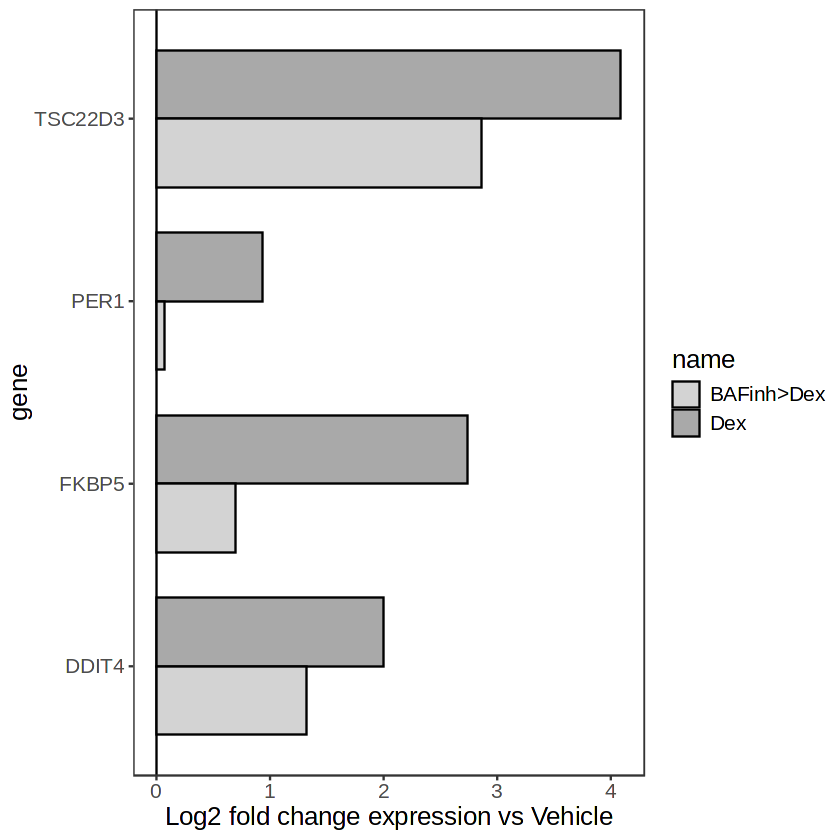

In [394]:
p1 <- inner_join(dex_6h[dex_6h$change=="up",], brm_dex_veh_6h[dex_6h$change=="up",], by="gene") %>% filter(gene %in% c("TSC22D3", "FKBP5", "PER1", "DDIT4")) %>% select(gene, Dex=log2FoldChange.x, "BAFinh>Dex"=log2FoldChange.y) %>% pivot_longer(!gene) %>% 
    ggplot(aes(y=gene, x=value, fill=name)) + geom_vline(xintercept=0) + geom_col(color="black",width=.75,position=position_dodge()) + xlab("Log2 fold change expression vs Vehicle") + scale_fill_manual(values=c("lightgrey", "darkgray"))
p1
p2 <- inner_join(dex_6h[dex_6h$change=="up",], brm_6h[dex_6h$change=="up",], by="gene") %>% filter(gene %in% c("TSC22D3", "FKBP5", "PER1", "DDIT4")) %>% select(gene, stim=log2FoldChange.x, brm_stim=log2FoldChange.y) %>% pivot_longer(!gene) %>% 
    ggplot(aes(y=gene, x=value, fill=name)) + geom_vline(xintercept=0) + geom_col(width=.75,position=position_dodge())

p3 <- inner_join(dex_6h[dex_6h$change=="up",], brm_ifn_6h[dex_6h$change=="up",], by="gene") %>% filter(gene %in% c("TSC22D3", "FKBP5", "PER1", "DDIT4")) %>% select(gene, stim=log2FoldChange.x, brm_stim=log2FoldChange.y) %>% pivot_longer(!gene) %>% 
    ggplot(aes(y=gene, x=value, fill=name)) + geom_vline(xintercept=0) + geom_col(width=.75,position=position_dodge())